# Подготовка признаков и план оценки

## 1. Что известно о полях

[Zenodo](https://zenodo.org/records/10210178) называет AC_CLASS классом самолета,
а C40_BEARING направлением между самолетом и аэропортом. Полный словарь кодов
AC_CLASS, единицы и правило вычисления C40_BEARING для этого файла не установлены.

В [EUROCONTROL, приложение IV](https://www.eurocontrol.int/sites/default/files/2019-05/us-europe-comparison-of-atm-related-operational-performance.pdf)
BEARING_CROSS_40 описывает направление от аэропорта к точке пересечения.
Для связанного BEARING_CROSS_100 указаны север 0 и восток 90. Это полезный
контекст, но не доказательство тождества с полем нашего parquet. Не подменяем
bearing курсом самолета и не предполагаем совпадение имен автоматически.

Коды AC_CLASS сохраняем как номинальные строки: MJ, H, MT и другие, включая ZZ.
Неподтвержденный ZZ не превращается автоматически в пропуск. Таблицы частот
показывают наблюдаемое распределение, а не расшифровку кодов.

Этот ноутбук проверяет диапазоны, обучает только словари категорий на train
и фиксирует план оценки. Модели и метрики не рассчитываются. Историческая
доступность C40 / метаданных остается предположением ретроспективного анализа.

In [1]:
from pathlib import Path
from collections import Counter
import os,hashlib,json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/protocol_manifest.json').exists():
    if ROOT==ROOT.parent: raise FileNotFoundError('Сначала выполните 06_time_split.ipynb')
    ROOT=ROOT.parent
R=ROOT/'reports'; F=ROOT/'figures'; LOCAL=ROOT/'data'
protocol=json.loads((R/'protocol_manifest.json').read_text(encoding='utf-8'))
entry=next(x for x in json.loads((R/'verification.json').read_text(encoding='utf-8'))['inputs'] if x['stage']=='final')
DATA=Path(os.environ.get('SAMPLE_SELECTION_DATA_ROOT',ROOT.parents[1]))/entry['file'].replace(chr(92),'/')
if not DATA.exists(): DATA=LOCAL/'06_05_cases_excluded.parquet'
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
assert sha(DATA)==protocol['input_sha256']
split_path=LOCAL/'06_candidate_split_labels.parquet'
assert sha(split_path)==protocol['split_file_sha256']
labels=pq.read_table(split_path).to_pandas()
assert len(labels)==entry['rows'] and np.array_equal(labels.source_row,np.arange(len(labels)))
assert protocol['structural_checks_passed']
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']:plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
CAT=['airport','typecode','icaoaircrafttype','AC_CLASS']
parts=['train','validation','test']
counts={(s,f):Counter() for s in parts for f in CAT}
missing={(s,f):0 for s in parts for f in CAT}
numeric=[]; hist={s:np.zeros(36,dtype=np.int64) for s in parts}
rows={s:0 for s in parts}; offset=0


## 2. Диапазоны и сырые категории по временным частям

Null / точная пустая строка — missing. Остальные строки сохраняют регистр и
пробелы. Диапазон bearing [0, 360) — диагностическая гипотеза градусов;
соответствие диапазону не подтверждает единицы, направление или время получения.

In [2]:
reader=pq.ParquetFile(DATA)
for batch in reader.iter_batches(batch_size=200000,columns=CAT+['C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON']):
    d=batch.to_pandas(); split=labels.split.iloc[offset:offset+len(d)].to_numpy();offset+=len(d)
    for s in parts:
        a=d[split==s]; rows[s]+=len(a)
        for f in CAT:
            m=a[f].isna()|a[f].eq('').fillna(False); missing[(s,f)]+=int(m.sum())
            counts[(s,f)].update({k:int(v) for k,v in a.loc[~m,f].value_counts().items()})
        for f,lo,hi in [('C40_CROSS_LAT',-90,90),('C40_CROSS_LON',-180,180),('C40_BEARING',0,360)]:
            x=a[f].to_numpy();finite=np.isfinite(x)
            invalid=finite & ((x<lo)|(x>=hi if f=='C40_BEARING' else x>hi))
            numeric.append({'split':s,'field':f,'rows':len(x),'nonfinite':int((~finite).sum()),
                            'outside_assumed_range':int(invalid.sum()),
                            'minimum':float(np.min(x[finite])) if finite.any() else np.nan,
                            'maximum':float(np.max(x[finite])) if finite.any() else np.nan,
                            'finite_rows':int(finite.sum()),'sum':float(x[finite].sum()),
                            'sum_sq':float(np.square(x[finite]).sum())})
        hist[s]+=np.histogram(a.C40_BEARING.to_numpy(),bins=np.linspace(0,360,37))[0]
del reader
assert offset==len(labels)
numeric=pd.DataFrame(numeric).groupby(['split','field']).agg(rows=('rows','sum'),
 nonfinite=('nonfinite','sum'),outside_assumed_range=('outside_assumed_range','sum'),
 minimum=('minimum','min'),maximum=('maximum','max'),finite_rows=('finite_rows','sum'),
 sum=('sum','sum'),sum_sq=('sum_sq','sum')).reset_index()
numeric.to_csv(R/'preparation_numeric_audit.csv',index=False);display(numeric)
raw=pd.DataFrame([{'split':s,'field':f,'raw_value':value,'rows':n}
 for (s,f),counter in counts.items() for value,n in counter.items()])
raw.to_csv(R/'preparation_category_counts.csv',index=False)
display(raw[raw.field.eq('AC_CLASS')].sort_values(['split','rows'],ascending=[True,False]))


,split,field,rows,nonfinite,outside_assumed_range,minimum,maximum,finite_rows,sum,sum_sq
0,test,C40_BEARING,546577,0,0,0.000000,359.984274,546577,9.737608e+07,2.256661e+10
1,test,C40_CROSS_LAT,546577,0,0,39.805556,60.318889,546577,2.665778e+07,1.310844e+09
2,test,C40_CROSS_LON,546577,0,0,-7.388611,22.055833,546577,3.113867e+06,4.695255e+07
3,train,C40_BEARING,4161493,0,0,0.000000,359.988163,4161493,7.070675e+08,1.596841e+11
4,train,C40_CROSS_LAT,4161493,0,0,39.805278,60.319167,4161493,2.057540e+08,1.025051e+10
5,train,C40_CROSS_LON,4161493,0,0,-7.393611,22.058889,4161493,2.617964e+07,3.504942e+08
6,validation,C40_BEARING,1619847,0,0,0.000000,359.986743,1619847,2.862530e+08,6.575940e+10
7,validation,C40_CROSS_LAT,1619847,0,0,39.805278,60.319722,1619847,7.995741e+07,3.975913e+09
8,validation,C40_CROSS_LON,1619847,0,0,-7.390833,22.057778,1619847,1.013300e+07,1.372788e+08


,split,field,raw_value,rows
964,test,AC_CLASS,MJ,438852
965,test,AC_CLASS,H,95943
966,test,AC_CLASS,MT,7156
967,test,AC_CLASS,LJ,3399
968,test,AC_CLASS,LT,1034
969,test,AC_CLASS,ZZ,147
970,test,AC_CLASS,LP,46
363,train,AC_CLASS,MJ,3256865
364,train,AC_CLASS,H,790848
365,train,AC_CLASS,MT,75169


## 3. Словари fit только на train

Для каждого поля — точные уникальные строки train, отсортированные для
воспроизводимости. При применении: missing имеет код −1, unseen имеет код −2,
видимая train-категория — свой индекс ≥0. Индекс служит идентификатором категории,
не числовым признаком: в будущей модели применяется разреженное one-hot
кодирование с отдельными колонками missing / unseen. Редкие значения не
объединяем по частотам test. Исходные поля не перезаписываются.

Словарь последующих частей используется только для диагностики OOV; он не
добавляет колонки в fit. [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
служит возможной реализацией, но его штатное поведение unknown нужно согласовать
с отдельным состоянием unseen: здесь фиксируется контракт, а не вызов encoder.

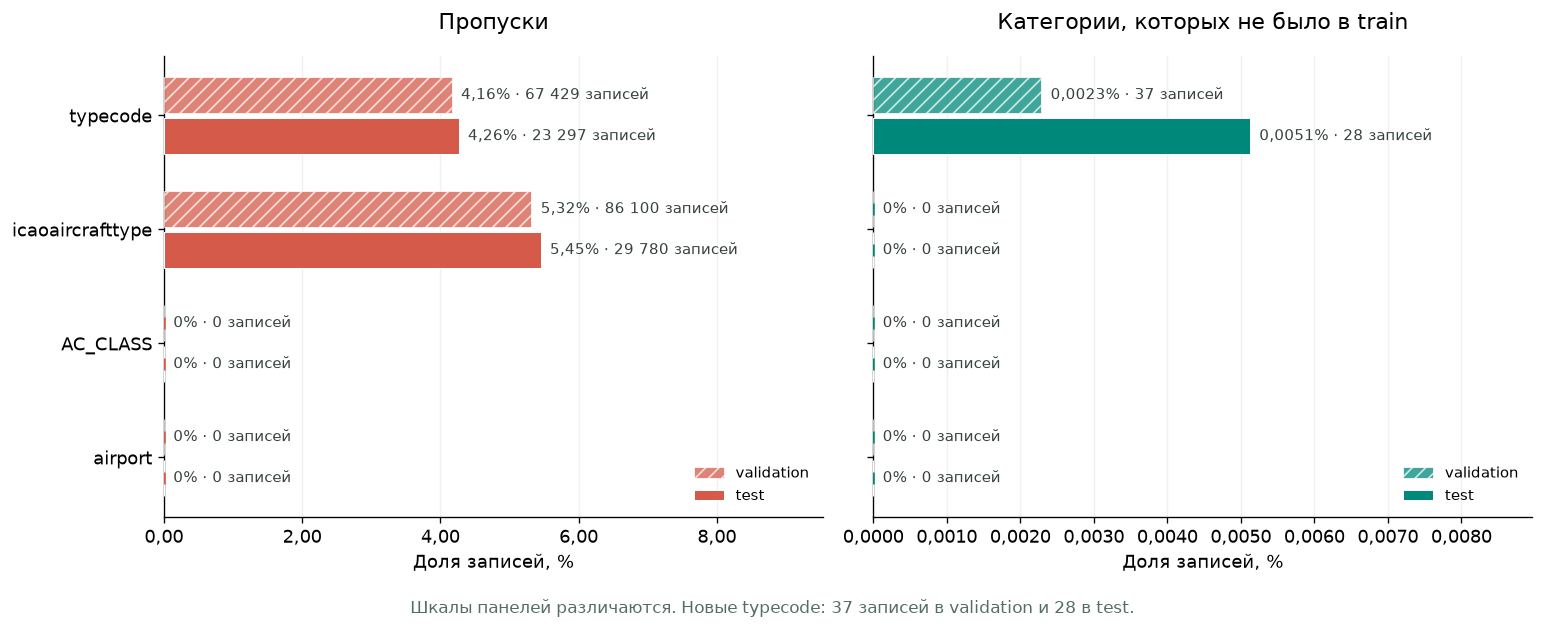

In [3]:
vocab={f:sorted(counts[('train',f)]) for f in CAT}
mapping={f:{value:i for i,value in enumerate(vocab[f])} for f in CAT}
def category_id(value,field):
    if pd.isna(value) or value=='':return -1
    return mapping[field].get(value,-2)
assert category_id(None,'typecode')==-1 and category_id('','typecode')==-1
unknown_example='__diagnostic_unseen__'
assert unknown_example not in mapping['typecode'] and category_id(unknown_example,'typecode')==-2
if 'ZZ' in mapping['AC_CLASS']:assert category_id('ZZ','AC_CLASS')>=0
states=[]
for s in parts:
    for f in CAT:
        seen=sum(n for v,n in counts[(s,f)].items() if v in mapping[f])
        unseen=sum(n for v,n in counts[(s,f)].items() if v not in mapping[f])
        for state,n in [('seen',seen),('missing',missing[(s,f)]),('unseen',unseen)]:
            states.append({'split':s,'field':f,'state':state,'rows':n,'pct':100*n/rows[s]})
states=pd.DataFrame(states);states.to_csv(R/'preparation_category_states.csv',index=False)
assert states[states.state.eq('unseen')&states.split.eq('train')].rows.sum()==0
for s in parts:
    assert states[states.split.eq(s)].groupby('field').rows.sum().eq(rows[s]).all()
(R/'preparation_train_vocabulary.json').write_text(json.dumps(
 {'fit_split':'train','input_sha256':protocol['input_sha256'],'vocabulary':vocab,
  'missing_id':-1,'unseen_id':-2,'category_indices_are_nominal':True},ensure_ascii=False,indent=2),encoding='utf-8')
display(states[states.state.ne('seen')].pivot(index=['field','split'],columns='state',values='pct').style.format(precision=3))
from matplotlib.ticker import FuncFormatter
fields=['typecode','icaoaircrafttype','AC_CLASS','airport']
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,state,color,title,digits in zip(axes,['missing','unseen'],['#D65A4A','#00897B'],
        ['Пропуски','Категории, которых не было в train'],[2,4]):
    panel=states[states.state.eq(state)&states.split.isin(['validation','test'])]
    maximum=float(panel.pct.max())
    span=maximum if maximum>0 else 1.0
    for split,offset,hatch,alpha in [('validation',-.18,'///',.75),('test',.18,None,1.0)]:
        values=panel[panel.split.eq(split)].set_index('field').reindex(fields)
        positions=np.arange(len(fields))+offset
        ax.barh(positions,values.pct,height=.32,color=color,alpha=alpha,
                hatch=hatch,edgecolor='white',linewidth=.6,label=split,zorder=3)
        for y,n,pct in zip(positions,values.rows,values.pct):
            percent=(f'{pct:.{digits}f}' if pct else '0').replace('.',',')
            count=f'{int(n):,}'.replace(',',' ')
            ax.text(float(pct)+span*.025,y,f'{percent}% · {count} записей',
                    va='center',fontsize=9,color='#37423D')
            if pct==0:ax.scatter([0],[y],marker='|',s=60,color=color,zorder=4)
    ax.set_yticks(np.arange(len(fields)),fields)
    ax.set_xlim(0,span*1.75)
    ax.set_title(title,pad=16,fontsize=13)
    ax.set_xlabel('Доля записей, %')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos,d=digits:f'{x:.{d}f}'.replace('.',',')))
    ax.grid(axis='y',visible=False);ax.grid(axis='x',alpha=.18)
    ax.legend(loc='lower right',fontsize=9,frameon=False)
axes[0].invert_yaxis()
fig.text(.5,-.035,'Шкалы панелей различаются. Новые typecode: 37 записей в validation и 28 в test.',
         ha='center',fontsize=10,color='#546E63')
save('22_category_missing_and_unseen')


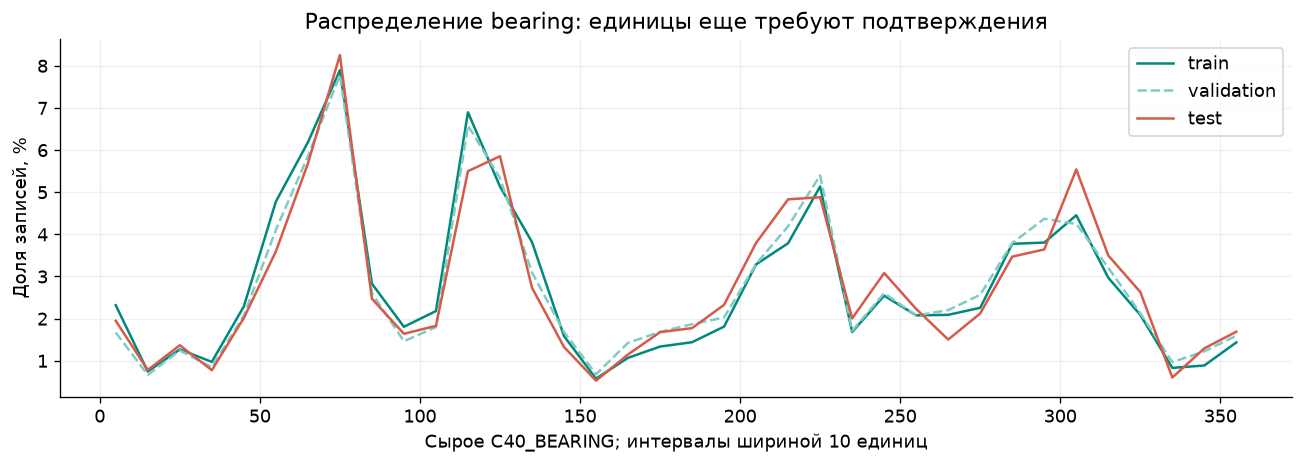

In [4]:
fig,ax=plt.subplots(figsize=(11,4))
centers=np.arange(5,360,10)
for s,color,style in [('train','#00897B','-'),('validation','#80CBC4','--'),('test','#D65A4A','-')]:
    ax.plot(centers,100*hist[s]/rows[s],label=s,color=color,linestyle=style)
ax.set_xlabel('Сырое C40_BEARING; интервалы шириной 10 единиц')
ax.set_ylabel('Доля записей, %');ax.set_title('Распределение bearing: единицы еще требуют подтверждения');ax.legend()
save('23_bearing_by_period')


## 4. Наборы и преобразования

Уточнение кандидатов из ноутбука 06: основной план сравнивает geometry и
geometry_aircraft, без bearing и AC_CLASS до закрытия их семантики.
Отдельные варианты bearing / raw_AC_CLASS сохраняются как условные проверки.
Время доступности остальных полей также не подтверждено; это не эксплуатационная
готовность. Все наборы используют одинаковый split и сохраняют пропуски.

Для будущего препроцессора: lat / lon — числовые признаки, standardization
с параметрами только train для линейной модели. UTC время дня — sin / cos
от секунд суток, день недели — семь фиксированных категорий. Ни абсолютный
год, ни landing_time не используются. Bearing sin / cos допускается только
после подтверждения градусов; данные не приводятся к диапазону автоматически.

## 5. План оценки — до обучения

Основная метрика — average precision (AP), дополнительно ROC-AUC, Brier score
и калибровка. [AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)
не называется площадью под PR-кривой по правилу трапеций: это разные расчеты.
Все вероятности и метрики оценивать на одинаковых строках для каждого набора.

Первый ориентир — константная вероятность из частоты train; первый обучаемый
кандидат — логистическая регрессия с заранее определенным разреженным one-hot.
Подбор регуляризации и проверка вариантов только validation. Без автоматического
балансирования классов: оно меняет смысл вероятностей и требует отдельной проверки.
Test используется один раз после фиксации модели, признаков и порога.

Пороговый план: заранее выбрать на validation максимальный F1, при равенстве
взять более высокий порог. Это исследовательский критерий, не эксплуатационная
полезность и не стоимость ошибки FP. Отчет включает precision, recall,
число и долю тревог; возможный рабочий порог потребует требований применения.

Публиковать pooled-метрики и таблицу по аэропортам с числом GoA. Для группы без
положительных меток AP / recall не интерпретировать; для одной метки ROC-AUC
не вычислять. Test не оценивает EGCC. Части года и смена состава аэропортов
входят в ограничения. AP train-частоты — ориентир, не оценка качества модели.

Для интервалов планируется парный bootstrap блоков по неделям C40 UTC на test:
1000 повторов, seed=42, одинаковые блоки для сравниваемых моделей. Это учитывает
часть временной зависимости, но не доказывает независимость блоков или учитывает
всю зависимость по самолету. Проверка других длин блоков остается запланированной.
Bootstrap с одной меткой помечается недопустимым для ROC-AUC; число допустимых
повторов сообщается. Никакие интервалы в этом ноутбуке не рассчитаны.

In [5]:
# Фиксированные UTC-преобразования не обучаются на validation / test.
def utc_features(timestamps):
    t=pd.Series(pd.to_datetime(timestamps,utc=True))
    seconds=t.dt.hour*3600+t.dt.minute*60+t.dt.second+t.dt.microsecond/1e6
    phase=2*np.pi*seconds/86400
    return pd.DataFrame({'utc_time_sin':np.sin(phase),'utc_time_cos':np.cos(phase),
                         'utc_weekday':t.dt.dayofweek})
example=utc_features(['2020-01-01T00:00:00Z','2020-01-01T12:00:00Z'])
assert np.allclose(example.utc_time_cos,[1,-1])
assert np.allclose(example.utc_time_sin**2+example.utc_time_cos**2,1)
scaler={}
for f in ['C40_CROSS_LAT','C40_CROSS_LON']:
    a=numeric[numeric.split.eq('train')&numeric.field.eq(f)].iloc[0]
    assert a.nonfinite==0 and a.outside_assumed_range==0
    mean=a['sum']/a.finite_rows
    variance=max(0,a.sum_sq/a.finite_rows-mean**2)
    scaler[f]={'mean':float(mean),'scale':float(np.sqrt(variance)),'fit_rows':int(a.finite_rows)}
    assert scaler[f]['scale']>0
(R/'preparation_numeric_scaler.json').write_text(json.dumps(
 {'fit_split':'train','parameters':scaler,'input_sha256':protocol['input_sha256']},indent=2),encoding='utf-8')
display(pd.DataFrame(scaler).T)
base=['airport','C40_CROSS_LAT','C40_CROSS_LON','utc_time_sin','utc_time_cos','utc_weekday']
sets={'geometry':base,'geometry_aircraft':base+['typecode','icaoaircrafttype'],
      'conditional_bearing':base+['bearing_sin','bearing_cos'],
      'conditional_raw_class':base+['typecode','icaoaircrafttype','AC_CLASS']}
plan={'status':'retrospective_evaluation_plan_not_executed','input_sha256':protocol['input_sha256'],
 'split_file_sha256':protocol['split_file_sha256'],'feature_sets':sets,
 'primary_comparison':['geometry','geometry_aircraft'],
 'conditional_features':['bearing_sin','bearing_cos','AC_CLASS'],
 'raw_values_preserved':True,'fit_categories_split':'train','vocabulary_sizes':{f:len(v) for f,v in vocab.items()},
 'missing_id':-1,'unseen_id':-2,'encoding':'sparse one-hot; separate missing/unseen columns',
 'metrics':['average_precision','ROC_AUC','Brier','calibration'],
 'threshold_selection':'validation maximum F1; ties choose higher threshold',
 'model_plan':{'baseline':'train prevalence constant','candidate':'logistic regression L2',
               'C_grid':[0.01,0.1,1.0,10.0],'selection':'validation AP; ties lower C',
               'class_weight':None,'refit_train_validation':False},
 'numeric_scaler_fit_split':'train','utc_transform_implemented':True,
 'bootstrap_plan':{'block':'C40 ISO week UTC','replicates':1000,'seed':42,'paired':True,'executed':False},
 'operational_availability_verified':False,'classifier_training_performed':False,
 'test_metrics_computed':False,'category_balances_passed':True,'input_unchanged':True}
assert sha(DATA)==protocol['input_sha256'] and sha(split_path)==protocol['split_file_sha256']
assert not any(f in {'GoA','landing_time','attempt_times','flight_id','icao24','market_segment'} for fs in sets.values() for f in fs)
(R/'preparation_plan.json').write_text(json.dumps(plan,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame([{'set':s,'features':', '.join(fs),
 'status':'условная проверка семантики' if s.startswith('conditional') else 'основной ретроспективный кандидат'} for s,fs in sets.items()]))
display(Markdown('Словари train и диагностика готовы. Исходные поля не изменены. '
 'План оценки сохранен; классификатор, метрики и интервалы не вычислялись.'))


,mean,scale,fit_rows
C40_CROSS_LAT,49.442342,4.316990,4161493.0
C40_CROSS_LON,6.290926,6.681873,4161493.0


,set,features,status
0,geometry,"airport, C40_CROSS_LAT, C40_CROSS_LON, utc_tim...",основной ретроспективный кандидат
1,geometry_aircraft,"airport, C40_CROSS_LAT, C40_CROSS_LON, utc_tim...",основной ретроспективный кандидат
2,conditional_bearing,"airport, C40_CROSS_LAT, C40_CROSS_LON, utc_tim...",условная проверка семантики
3,conditional_raw_class,"airport, C40_CROSS_LAT, C40_CROSS_LON, utc_tim...",условная проверка семантики


Словари train и диагностика готовы. Исходные поля не изменены. План оценки сохранен; классификатор, метрики и интервалы не вычислялись.